In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [41]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [43]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [44]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [46]:
df.duplicated().sum()

0

In [47]:
df["customerID"].duplicated().sum()

0

In [48]:
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    print(f"\n {col}: ")
    print(df[col].value_counts(dropna=False))


 customerID: 
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

 gender: 
gender
Male      3555
Female    3488
Name: count, dtype: int64

 Partner: 
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Dependents: 
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 PhoneService: 
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

 MultipleLines: 
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

 InternetService: 
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 OnlineSecurity: 
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

 OnlineBackup: 
OnlineBackup
No                     3088
Y

In [49]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [50]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [51]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [52]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [54]:
display(df[df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,0
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,0
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,0
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,0
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,0
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,0
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,0
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,0
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,0
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,0


In [55]:
print(df["TotalCharges"].isnull().sum())

11


In [56]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values:", df.isnull().sum())
print("Data Type:", df["TotalCharges"].dtype)
print("Zero_tenure:", (df["tenure"] == 0).sum())

Missing values: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Data Type: float64
Zero_tenure: 11


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [58]:
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [59]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [60]:
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)
contract_table.columns = ["stayed", "churned"]
contract_table["Total"] = (
    contract_table["stayed"] +
    contract_table["churned"]
)
contract_table["churn rate (%)"] = (
    contract_table["churned"] / contract_table["Total"] * 100
)

display(contract_table.round(2))

,stayed,churned,Total,churn rate (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


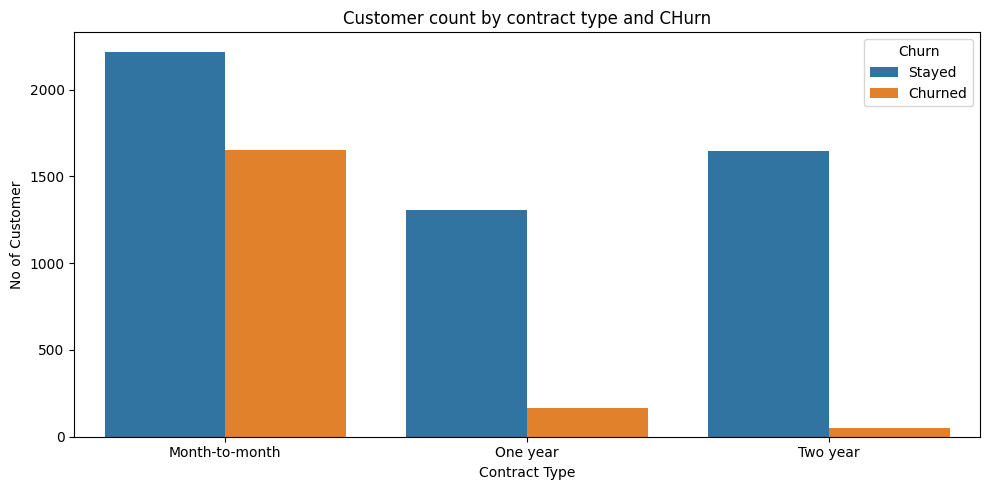

In [61]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)
plt.title("Customer count by contract type and CHurn")
plt.xlabel("Contract Type")
plt.ylabel("No of Customer")
plt.legend(title="Churn", labels=["Stayed", "Churned"])
plt.tight_layout()
plt.show()

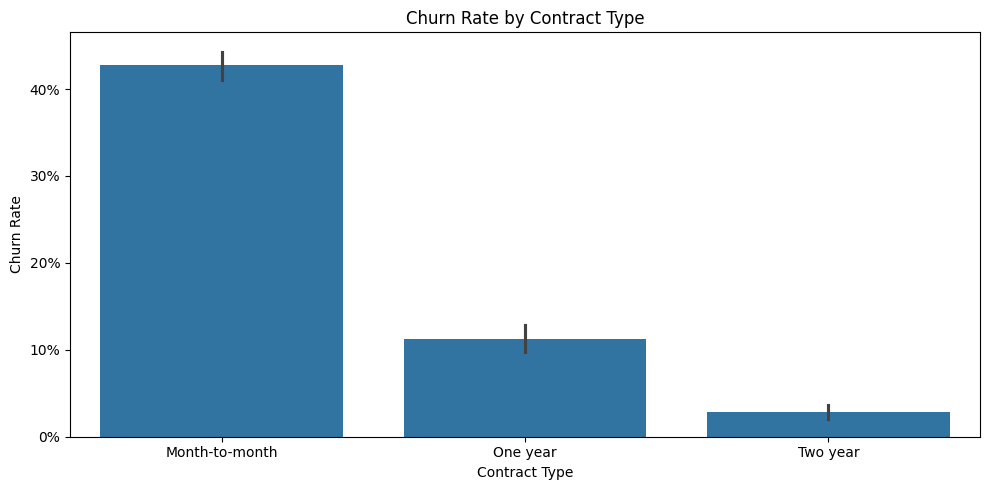

In [62]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Contract",
    y="Churn"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

In [63]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [64]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]
num_summ = df.groupby("Churn")[numerical_features].agg(
    ["count", "mean", "median", "std"]
)
display(num_summ.round(2))

tenure                      MonthlyCharges                       \
       count   mean median    std          count   mean median    std   
Churn                                                                   
0       5174  37.57   38.0  24.11           5174  61.27  64.43  31.09   
1       1869  17.98   10.0  19.53           1869  74.44  79.65  24.67   

      TotalCharges                             
             count     mean   median      std  
Churn                                          
0             5174  2549.91  1679.52  2329.95  
1             1869  1531.80   703.55  1890.82

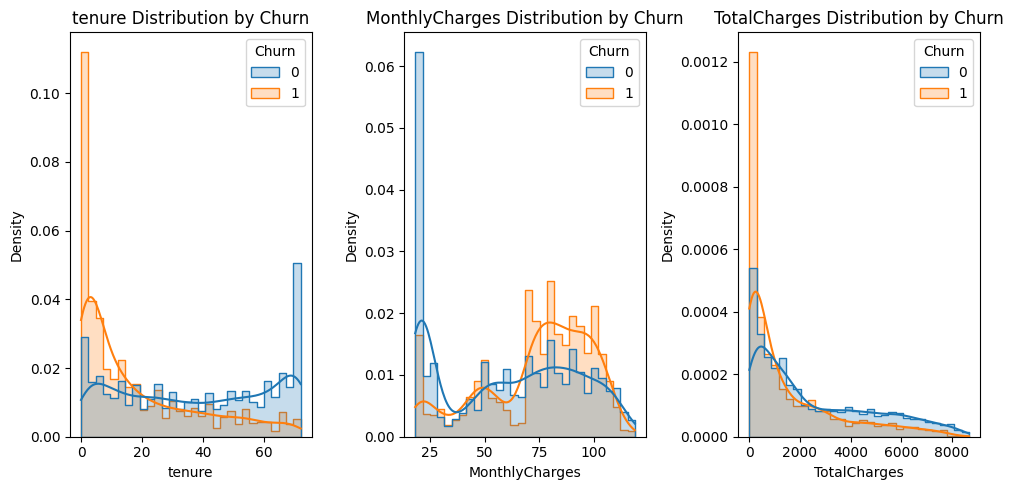

In [65]:
fig, axes = plt.subplots(1,3, figsize=(10,5))
for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Churn",
        bins=30,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} Distribution by Churn")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

plt.tight_layout()
plt.show()

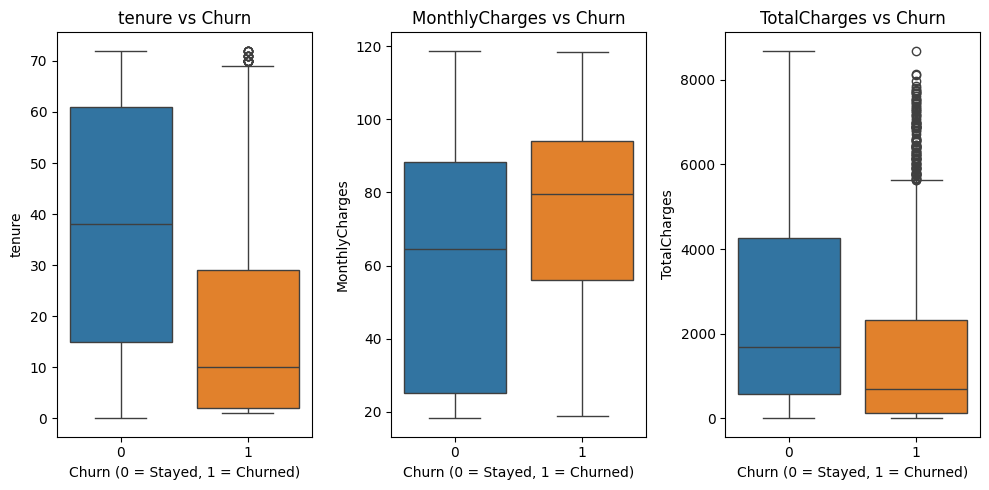

In [66]:
fig, axes = plt.subplots(1,3, figsize=(10,5))
for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x="Churn",
        y=feature,
        hue="Churn",
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Churn")
    axes[i].set_xlabel("Churn (0 = Stayed, 1 = Churned)")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


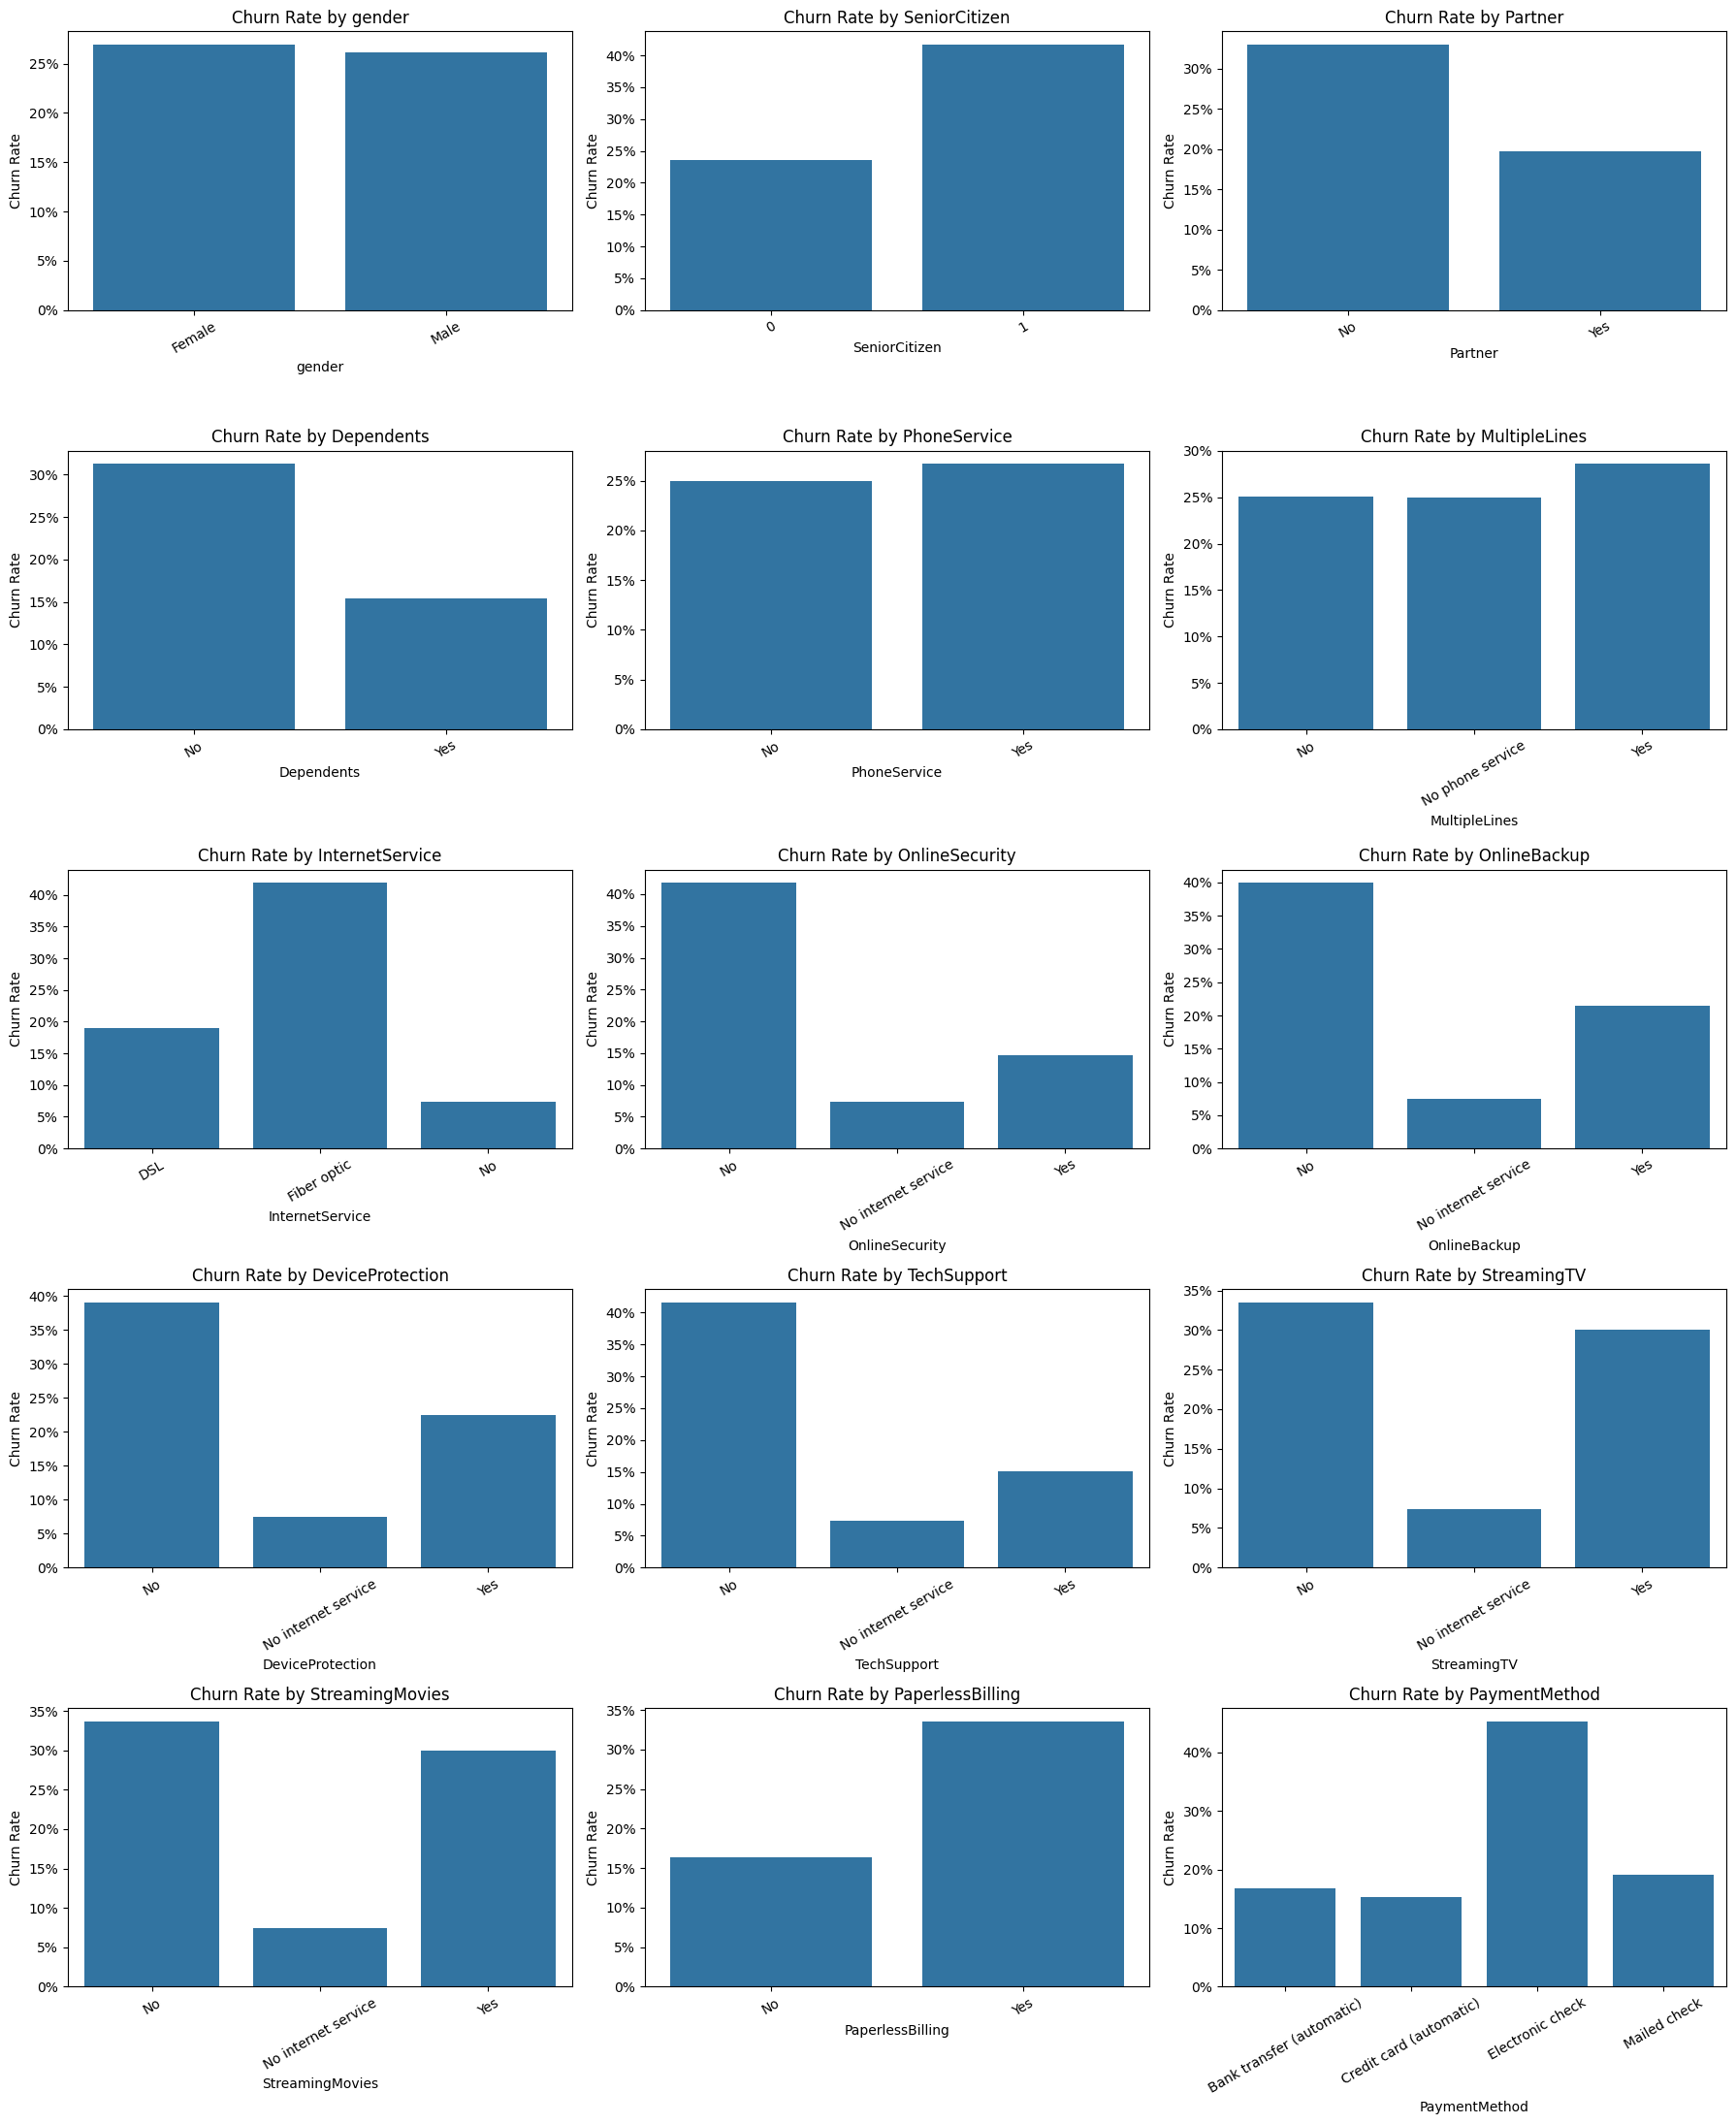

In [68]:
categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling",
    "PaymentMethod"
]

fig, axes = plt.subplots(5, 3, figsize=(18, 22))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    # Calculate churn rate for each category
    churn_rate = df.groupby(feature)["Churn"].mean()

    # Create bar chart
    sns.barplot(
        x=churn_rate.index.astype(str),
        y=churn_rate.values,
        ax=axes[i]
    )

    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Churn Rate")

    axes[i].yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0%}")
    )

    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [69]:
categorical_summary = []
for feature in categorical_features:
    summary = df.groupby(feature)["Churn"].agg(
        Total_Customers="count",
        Churned="sum",
        Churn_Rate="mean"
    ).reset_index()

    summary["Feature"] = feature
    summary.rename(
        columns={feature: "Category"},
        inplace=True
    )

    categorical_summary.append(summary)

categorical_summary = pd.concat(
    categorical_summary,
    ignore_index=True
)

categorical_summary["Churn_Rate"] *= 100

display(
    categorical_summary[
        ["Feature", "Category", "Total_Customers",
         "Churned", "Churn_Rate"]
    ].round(2).sort_values(
        "Churn_Rate", ascending=False
    )
)


,Feature,Category,Total_Customers,Churned,Churn_Rate
38,PaymentMethod,Electronic check,2365,1071,45.29
14,InternetService,Fiber optic,3096,1297,41.89
16,OnlineSecurity,No,3498,1461,41.77
3,SeniorCitizen,1,1142,476,41.68
25,TechSupport,No,3473,1446,41.64
19,OnlineBackup,No,3088,1233,39.93
22,DeviceProtection,No,3095,1211,39.13
31,StreamingMovies,No,2785,938,33.68
35,PaperlessBilling,Yes,4171,1400,33.57
28,StreamingTV,No,2810,942,33.52


In [71]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [80]:
categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

categorical_summary = []
for feature in categorical_features:
    summary = df.groupby(feature)["Churn"].agg(
        Total_Customers = "count",
        Churned = "sum",
        Churn_Rate = "mean"
    ).reset_index()

    summary["Feature"] = feature
    summary.rename(
        columns={feature: "Category"},
        inplace=True
    )
    categorical_summary.append(summary)

categorical_summary = pd.concat(
    categorical_summary,
    ignore_index=True
)

categorical_summary["Churn_Rate"] *= 100

display(
    categorical_summary[
        ["Feature", "Category", "Total_Customers", "Churned", "Churn_Rate"]
    ].round(2).sort_values(
        "Churn_Rate", ascending=False
    )
)

,Feature,Category,Total_Customers,Churned,Churn_Rate
41,PaymentMethod,Electronic check,2365,1071,45.29
34,Contract,Month-to-month,3875,1655,42.71
14,InternetService,Fiber optic,3096,1297,41.89
16,OnlineSecurity,No,3498,1461,41.77
3,SeniorCitizen,1,1142,476,41.68
25,TechSupport,No,3473,1446,41.64
19,OnlineBackup,No,3088,1233,39.93
22,DeviceProtection,No,3095,1211,39.13
31,StreamingMovies,No,2785,938,33.68
38,PaperlessBilling,Yes,4171,1400,33.57


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [82]:
df = df.copy()
df = df.drop(columns=["customerID"], errors="ignore")

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [84]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [85]:
X= df.drop(columns="Churn", axis=1)
y=df["Churn"]

In [86]:
X.shape, y.shape

((7043, 19), (7043,))

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [88]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 19), (1409, 19), (5634,), (1409,))

In [90]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
] #StandardScaler
categorical_features = [
    col for col in X.columns
    if col not in numerical_features
    and col != "SeniorCitizen"
] #OneHotEncoder

binary_features = ["SeniorCitizen"]

In [92]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [93]:
numerical_tansformer =  StandardScaler()
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_tansformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
        ("binary", "passthrough", binary_features)
    ]
)

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "LR": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "DT": DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ),
    "RF": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
}

In [96]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [97]:
print("Original data:")
print(X_train.head())

print("\nTransformed data:")
print(X_train_processed[:5])

print("Original shape:", X_train.shape)
print("Processed shape:", X_train_processed.shape)

Original data:
      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
3738    Male              0      No         No      35           No   
3151    Male              0     Yes        Yes      15          Yes   
4860    Male              0     Yes        Yes      13           No   
3867  Female              0     Yes         No      26          Yes   
3810    Male              0     Yes        Yes       1          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
3738  No phone service             DSL             No           No   
3151                No     Fiber optic            Yes           No   
4860  No phone service             DSL            Yes          Yes   
3867                No             DSL             No          Yes   
3810                No             DSL             No           No   

     DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
3738              Yes          No         Yes           

In [107]:
trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

LR trained successfully!
DT trained successfully!
RF trained successfully!


In [108]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="ROC-AUC",
    ascending=False
))

  Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
0    LR  0.738112   0.504303  0.783422  0.613613  0.841634
2    RF  0.767211   0.547325  0.711230  0.618605  0.837102
1    DT  0.754436   0.526022  0.756684  0.620614  0.831799


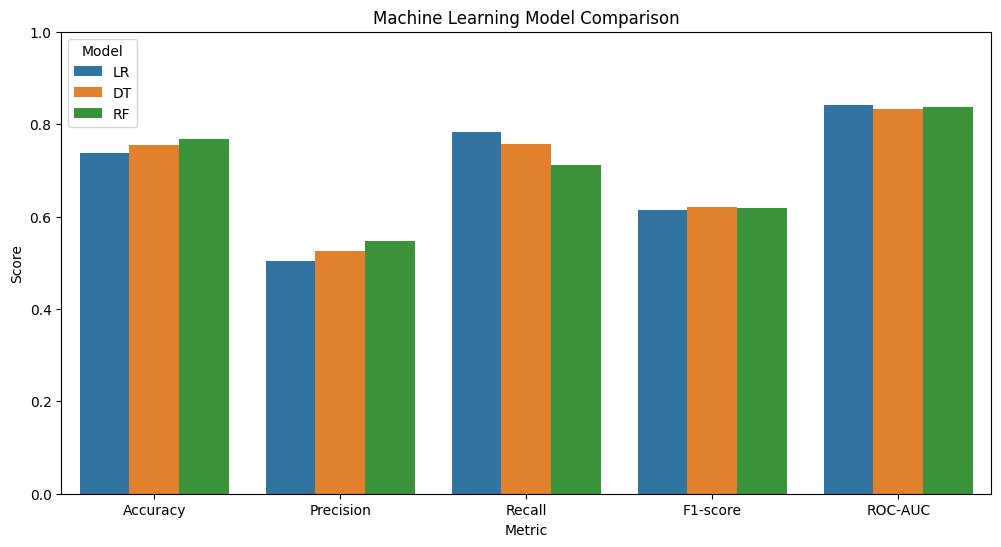

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Comparison")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.show()

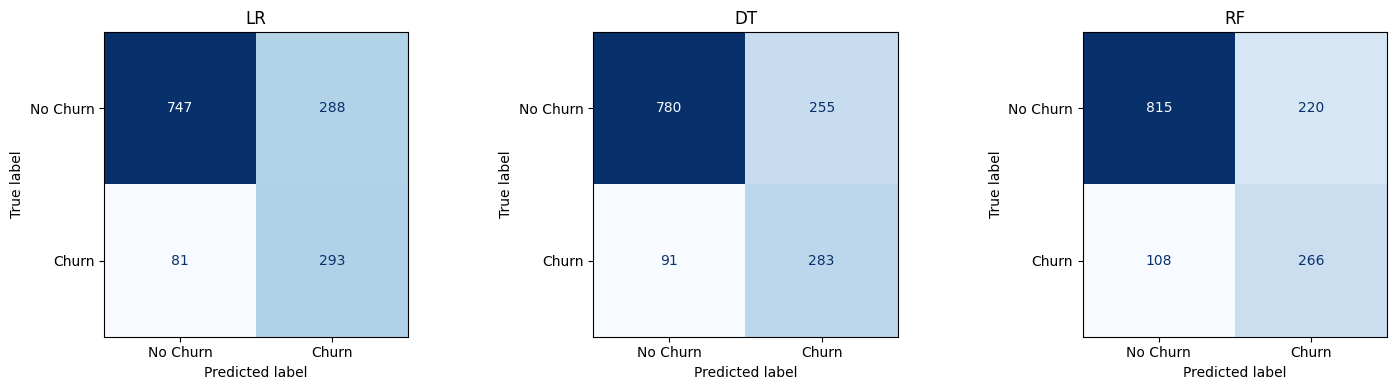

In [110]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Churn", "Churn"],
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [114]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation ROC-AUC:", grid_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'classifier__C': 100}
Best Cross-validation ROC-AUC: 0.8455738587820292


In [115]:
best_lr = grid_search.best_estimator_

y_pred_tuned = best_lr.predict(X_test)
y_prob_tuned = best_lr.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1-score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Accuracy: 0.7381121362668559
Precision: 0.5043177892918825
Recall: 0.7807486631016043
F1-score: 0.6128016789087093
ROC-AUC: 0.840329122426309

Confusion Matrix:
[[748 287]
 [ 82 292]]


In [116]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from scipy.stats import randint

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

param_dist = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [5, 10, 15, 20, None],
    "classifier__min_samples_split": randint(2, 20),
    "classifier__min_samples_leaf": randint(1, 10),
    "classifier__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best Cross-validation ROC-AUC:", rf_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 7, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Best Cross-validation ROC-AUC: 0.8485970697840646


In [117]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

best_rf = rf_search.best_estimator_

# Predictions
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

# Evaluation
print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Tuned Random Forest
Accuracy: 0.7672107877927609
Precision: 0.5433962264150943
Recall: 0.7700534759358288
F1-score: 0.6371681415929203
ROC-AUC: 0.8434782608695652

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.77      0.83      1035
           1       0.54      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409

Confusion Matrix:
[[793 242]
 [ 86 288]]


In [118]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

param_grid_dt = {
    "classifier__max_depth": [3, 5, 7, 10, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__criterion": ["gini", "entropy"]
}

dt_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

dt_search.fit(X_train, y_train)

print("Best Parameters:", dt_search.best_params_)
print("Best Cross-validation ROC-AUC:", dt_search.best_score_)

Fitting 5 folds for each of 224 candidates, totalling 1120 fits
Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}
Best Cross-validation ROC-AUC: 0.8280367978547678


In [119]:
best_dt = dt_search.best_estimator_

# Predictions
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

# Evaluation
print("Tuned Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Tuned Decision Tree
Accuracy: 0.7537260468417317
Precision: 0.525328330206379
Recall: 0.7486631016042781
F1-score: 0.61742006615215
ROC-AUC: 0.8370521067452014

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      1035
           1       0.53      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.77      1409

Confusion Matrix:
[[782 253]
 [ 94 280]]


In [120]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_train_prob = cross_val_predict(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Training probabilities generated!")
print("Number of predictions:", len(y_train_prob))

Training probabilities generated!
Number of predictions: 5634


In [121]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_train_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, y_pred_threshold),
        "Precision": precision_score(y_train, y_pred_threshold),
        "Recall": recall_score(y_train, y_pred_threshold),
        "F1-score": f1_score(y_train, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Accuracy  Precision  Recall  F1-score
0       0.30    0.6771     0.4464  0.9030    0.5975
1       0.35    0.7022     0.4671  0.8696    0.6078
2       0.40    0.7293     0.4941  0.8441    0.6234
3       0.45    0.7543     0.5242  0.8027    0.6342
4       0.50    0.7691     0.5468  0.7585    0.6355
5       0.55    0.7806     0.5707  0.6990    0.6284
6       0.60    0.7968     0.6113  0.6428    0.6267


In [122]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Get churn probabilities from tuned Random Forest
y_prob_final = best_rf.predict_proba(X_test)[:, 1]

# Apply selected threshold
selected_threshold = 0.45
y_pred_final = (y_prob_final >= selected_threshold).astype(int)

# Evaluate
print("Final Tuned Random Forest - Threshold 0.45")
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))
print("F1-score:", f1_score(y_test, y_pred_final))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final Tuned Random Forest - Threshold 0.45
Accuracy: 0.7480482611781405
Precision: 0.5161839863713799
Recall: 0.8101604278074866
F1-score: 0.6305931321540063
ROC-AUC: 0.8434782608695652

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

Confusion Matrix:
[[751 284]
 [ 71 303]]


In [125]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFirst 10 test samples:")
display(X_test.head(10))

print("\nActual churn values:")
print(y_test.head(10))

X_test shape: (1409, 19)
y_test shape: (1409,)

First 10 test samples:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,No,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),19.75,1311.60
1639,Male,1,No,No,17,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.05,770.60



Actual churn values:
437     0
2280    0
2235    0
4460    0
3761    0
5748    0
3568    0
2976    0
5928    0
1639    1
Name: Churn, dtype: int64


In [126]:
# Predict churn probabilities
y_prob_test = best_rf.predict_proba(X_test)[:, 1]

# Apply threshold of 0.45
y_pred_test = (y_prob_test >= 0.45).astype(int)

print("First 10 predicted probabilities:")
print(y_prob_test[:10])

print("\nFirst 10 predicted churn labels:")
print(y_pred_test[:10])

First 10 predicted probabilities:
[0.02988506 0.82710012 0.124035   0.50074705 0.04525476 0.76915093
 0.59056846 0.19052467 0.00454264 0.57051737]

First 10 predicted churn labels:
[0 1 0 1 0 1 1 0 0 1]


In [127]:
comparison = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": y_pred_test,
    "Churn_Probability": y_prob_test
})

display(comparison.head(20))

,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.029885
1,0,1,0.827100
2,0,0,0.124035
3,0,1,0.500747
4,0,0,0.045255
5,0,1,0.769151
6,0,1,0.590568
7,0,0,0.190525
8,0,0,0.004543
9,1,1,0.570517


In [128]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Final Test Results")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print("Precision:", precision_score(y_test, y_pred_test))
print("Recall:", recall_score(y_test, y_pred_test))
print("F1-score:", f1_score(y_test, y_pred_test))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

Final Test Results
Accuracy: 0.7480482611781405
Precision: 0.5161839863713799
Recall: 0.8101604278074866
F1-score: 0.6305931321540063
ROC-AUC: 0.8434782608695652

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

Confusion Matrix:
[[751 284]
 [ 71 303]]


In [129]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTotal Test Customers:", len(y_test))
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)

Confusion Matrix:
[[751 284]
 [ 71 303]]

Total Test Customers: 1409
True Negatives: 751
False Positives: 284
False Negatives: 71
True Positives: 303
Correct Predictions: 1054
Incorrect Predictions: 355


In [130]:
'''
Business interpretation
Imagine the company uses this model to identify customers for retention campaigns.
- Out of 374 customers who actually churned, the model identified 303.
- It missed 71 customers.
- It flagged 587 customers as potential churners.
- Of those 587, 303 actually churned.
This means the model identifies approximately 81 out of every 100 actual churners.

However, approximately 48% of its churn alerts are false positives. The business should consider whether contacting these customers is affordable.
'''

'\nBusiness interpretation\nImagine the company uses this model to identify customers for retention campaigns.\n- Out of 374 customers who actually churned, the model identified 303.\n- It missed 71 customers.\n- It flagged 587 customers as potential churners.\n- Of those 587, 303 actually churned.\nThis means the model identifies approximately 81 out of every 100 actual churners.\n\nHowever, approximately 48% of its churn alerts are false positives. The business should consider whether contacting these customers is affordable.\n'